In [1]:
# Импортируем библиотеки
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Загружаем данные
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='target')

# Соединяем для удобства анализа
df = X.copy()
df['target'] = y

In [6]:
# 1. Анализ структуры данных:
# Выведите на экран первые 5 строк полученного DataFrame с помощью метода .head().
# Выведите на экран список всех столбцов полученного DataFrame.
# Используя методы info() и describe(), проведите базовый анализ структуры и основных статистических характеристик данных.

# Первые 5 строк
print(df.head())



   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [7]:
# Список всех столбцов
print("\nСтолбцы:", df.columns.tolist())




Столбцы: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']


In [9]:
# Базовый анализ
print("\nИнформация о данных:")
print(df.info())




Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [10]:
print("\nСтатистические характеристики:")
print(df.describe())


Статистические характеристики:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453    

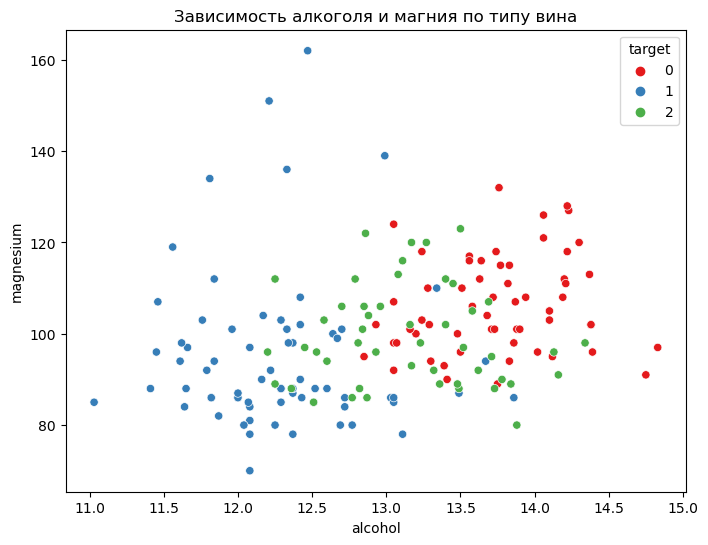

In [11]:
# 2. Визуализация данных:
# Используйте seaborn для создания scatterplot, показывающего зависимость между содержанием алкоголя и уровнем магния в вине, с разделением по типу вина.
# Создайте boxplot, отображающий распределение уровня алкоголя по сортам вина.

# Scatterplot алкоголь vs магний
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='alcohol', y='magnesium', hue='target', palette='Set1')
plt.title('Зависимость алкоголя и магния по типу вина')
plt.show()


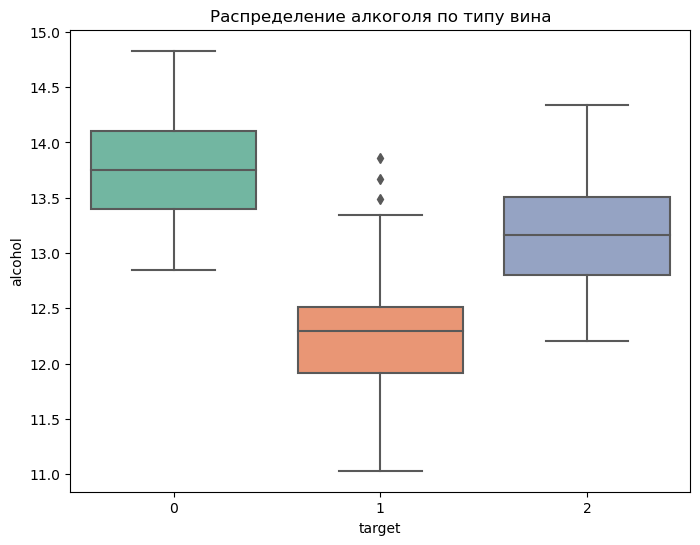

In [12]:
# Boxplot алкоголя по типу вина
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='target', y='alcohol', palette='Set2')
plt.title('Распределение алкоголя по типу вина')
plt.show()

In [4]:
# 3.Создание и обучение модели логистической регрессии:
# Создайте экземпляр модели LogisticRegression с параметрами max_iter=10000 и random_state=42. Обучите модель на обучающей выборке.

# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Создаём модель
model = LogisticRegression(max_iter=10000, random_state=42)

# Обучаем модель
model.fit(X_train, y_train)

LogisticRegression(max_iter=10000, random_state=42)

In [5]:
# 4. Оценка производительности модели:
# Сделайте предсказание на тестовых данных и вычислите точность модели с помощью accuracy_score. Проанализируйте результаты.

# Предсказание
y_pred = model.predict(X_test)

# Точность модели
accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочность модели на тестовых данных: {accuracy:.2f}")


Точность модели на тестовых данных: 1.00
